# Diseño de refracción sísmica para las terrazas ovaladas (Ciudad Perdida / Teyuna)

**Objetivo**: caracterizar el relleno de las dos terrazas hasta **2–3 m** de profundidad, en 3D, **trabajando solo dentro de la grama** (sin tocar muros ni anillos de piedra).

**Geometría** (aproximada de la foto aérea anotada):
- **Óvalo oeste**: ~18 m (N–S) × ~18 m (E–O).
- **Óvalo este**: ~22 m (E–O) × ~17 m (N–S).
- **Conjunto**: ~40 m de largo, unidos por un muro de piedra.

Todas las medidas deben confirmarse con estación total antes de replantear.

**Idea del diseño**: en cada óvalo, **3 tendidos de 24 canales que se cruzan en el centro** (0°, 60° y 120°). Para cada tendido se golpea:
- **a lo largo de la línea**, para el detalle somero y los offsets largos;
- **en un anillo de puntos junto al borde de la grama**, para tener rayos en todas las direcciones (3D).

Una **línea de enlace** opcional de 40 m une los dos óvalos.

**Sistema local**: origen en el extremo oeste del eje de 40 m, *x* hacia el este a lo largo del eje y *y* perpendicular.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Ellipse
from pathlib import Path
%matplotlib inline

# --- Terrazas (centro x, centro y, semieje x, semieje y), m ---
OVALS = {
    "Oeste": dict(cx=9.1, cy=0.0, a=9.1, b=9.0),
    "Este": dict(cx=29.0, cy=0.0, a=11.0, b=8.5),
}
WALL = 1.0             # m, ancho aproximado del anillo de piedra (solo para dibujar)
GEO_MARGIN = 0.3       # m, distancia mínima de un geófono al borde de piedra
SHOT_MARGIN = 0.7      # m, distancia mínima de un golpe al borde de piedra

# --- Tendidos ---
LINE_AZIMUTHS = [0, 60, 120]   # grados, diámetros que se cruzan en el centro
N_GEOPHONES = 23               # + canal 24 de referencia junto a la placa
GEO_DX = 0.75                  # m (tendido de 16.5 m)
INLINE_SHOT_DX = 1.5           # m, golpes a lo largo de la línea
RING_SHOT_DS = 3.0             # m, separación de golpes en el anillo perimetral
HITS_PER_SHOT = 8
MIN_PER_SHOT = 4               # min por posición de golpe (8 golpes + traslado)

# --- Línea de enlace entre óvalos (opcional) ---
LINK_DX = 1.0                  # m

# --- Modelo de velocidad ilustrativo: V(z) = V0 + GRAD z ---
V0, GRAD = 400.0, 150.0        # V(3 m) = 850 m/s
TARGET_DEPTHS = [2.0, 3.0]

EARTH = ["#eadbb8", "#c8a06e", "#8c6a4a", "#5a3d26"]
OUT = Path("design"); OUT.mkdir(exist_ok=True)

## 1. ¿Qué offset hace falta para 2–3 m?

Con una velocidad que crece con la profundidad, el rayo entre una fuente y un geófono separados $X$ es un arco. Su punto más profundo es

$$z_{max}(X) = \frac{V_0}{g}\left(\sqrt{1 + \left(\frac{g X}{2 V_0}\right)^2} - 1\right).$$

Los offsets necesarios caben dentro de cada óvalo, así que no hace falta salir de la terraza.

2 m de profundidad -> offset de ~7.7 m
3 m de profundidad -> offset de ~10.0 m


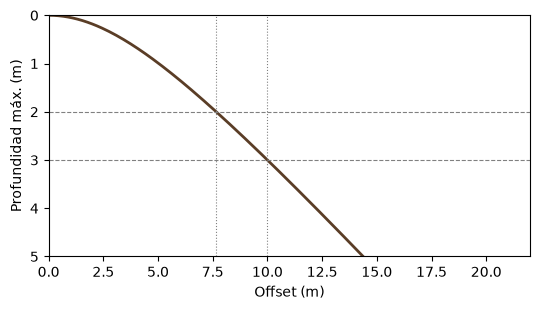

In [2]:
h = V0 / GRAD

def turning_depth(X):
    return h * (np.sqrt(1 + (GRAD * np.asarray(X, float) / (2 * V0)) ** 2) - 1)

def offset_for(z):
    return 2 * h * np.sqrt(((z + h) / h) ** 2 - 1)

def ray_depth(s, X):
    R = np.sqrt((X / 2) ** 2 + h ** 2)
    return np.clip(np.sqrt(np.maximum(R ** 2 - (s - X / 2) ** 2, 0)) - h, 0, None)

for z in TARGET_DEPTHS:
    print(f"{z:.0f} m de profundidad -> offset de ~{offset_for(z):.1f} m")

X = np.linspace(0, 22, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(X, turning_depth(X), color=EARTH[3], lw=2)
for z in TARGET_DEPTHS:
    ax.axhline(z, color="0.5", ls="--", lw=0.8)
    ax.axvline(offset_for(z), color="0.5", ls=":", lw=0.8)
ax.set_ylim(5, 0); ax.set_xlim(0, 22)
ax.set_xlabel("Offset (m)"); ax.set_ylabel("Profundidad máx. (m)")
plt.tight_layout(); plt.show()

## 2. Geometría del diseño

En cada óvalo:
- **3 tendidos** (0°, 60° y 120°) de 23 geófonos cada 0.75 m (16.5 m), centrados en el óvalo. El canal 24 queda en la placa como referencia del trigger.
- **Golpes en línea** cada 1.5 m desde un borde de la grama hasta el otro, incluidos los extremos más allá de los geófonos (offsets de hasta ~19 m).
- **Golpes en el anillo** cada ~3 m, a 0.7 m del borde de piedra. Cada tendido registra todos los golpes del anillo de su óvalo.

Los tendidos se registran **uno a la vez**. Los puntos de golpe del anillo y del centro se reutilizan en los 3 tendidos.

In [3]:
def inner_half_length(oval, az, margin):
    c, s = np.cos(np.deg2rad(az)), np.sin(np.deg2rad(az))
    return 1 / np.hypot(c / (oval["a"] - margin), s / (oval["b"] - margin))

def on_line(oval, az, t):
    a = np.deg2rad(az)
    t = np.asarray(t, float)
    return np.c_[oval["cx"] + t * np.cos(a), oval["cy"] + t * np.sin(a)]

def ring(oval, margin, ds):
    th = np.linspace(0, 2 * np.pi, 2000)
    x = (oval["a"] - margin) * np.cos(th); y = (oval["b"] - margin) * np.sin(th)
    s = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    n = int(round(s[-1] / ds))
    idx = np.searchsorted(s, np.arange(n) * s[-1] / n)
    return np.c_[oval["cx"] + x[idx], oval["cy"] + y[idx]]

spreads = []
for name, oval in OVALS.items():
    ring_shots = ring(oval, SHOT_MARGIN, RING_SHOT_DS)
    for az in LINE_AZIMUTHS:
        t_geo = (np.arange(N_GEOPHONES) - (N_GEOPHONES - 1) / 2) * GEO_DX
        t_geo = t_geo[np.abs(t_geo) <= inner_half_length(oval, az, GEO_MARGIN)]
        t_max = inner_half_length(oval, az, SHOT_MARGIN)
        t_shot = np.unique(np.r_[np.arange(0, t_max, INLINE_SHOT_DX), -np.arange(0, t_max, INLINE_SHOT_DX), t_max, -t_max])
        spreads.append(dict(oval=name, line=f"{name[0]}{az:03d}", az=az,
                            geophones=on_line(oval, az, t_geo),
                            inline=on_line(oval, az, t_shot), ring=ring_shots))

# Línea de enlace a lo largo del eje de 40 m (geófonos solo sobre grama)
x_link = np.arange(GEO_MARGIN, 40 - GEO_MARGIN + 1e-9, LINK_DX)
def in_grass(x, y, margin):
    return any(((x - o["cx"]) / (o["a"] - margin)) ** 2 + ((y - o["cy"]) / (o["b"] - margin)) ** 2 <= 1
               for o in OVALS.values())
link_geo = np.array([[x, 0.0] for x in x_link if in_grass(x, 0.0, GEO_MARGIN)])
link_shots = np.array([[SHOT_MARGIN, 0.0], [10.0, 0.0], [18.0, 0.0], [22.0, 0.0], [30.0, 0.0], [40 - SHOT_MARGIN, 0.0]])

plan = pd.DataFrame([{
    "tendido": sp["line"], "óvalo": sp["oval"], "geófonos": len(sp["geophones"]),
    "golpes en línea": len(sp["inline"]), "golpes anillo": len(sp["ring"]),
    "golpes": (len(sp["inline"]) + len(sp["ring"])) * HITS_PER_SHOT,
    "trazas": (len(sp["inline"]) + len(sp["ring"])) * len(sp["geophones"]),
    "offset máx. (m)": round(max(np.hypot(*(g - s)) for s in np.vstack([sp["inline"], sp["ring"]]) for g in sp["geophones"]), 1),
} for sp in spreads]).set_index("tendido")
total_positions = (plan["golpes en línea"] + plan["golpes anillo"]).sum()
print(f"Total: {len(spreads)} tendidos, {total_positions} posiciones de golpe, "
      f"{plan['golpes'].sum()} golpes, {plan['trazas'].sum()} trazas, "
      f"~{total_positions * MIN_PER_SHOT / 60:.0f} h de registro (sin contar montaje)")
print(f"Línea de enlace (opcional): {len(link_geo)} geófonos (2 tendidos de 24 canales), {len(link_shots)} golpes")
plan

Total: 6 tendidos, 188 posiciones de golpe, 1504 golpes, 4324 trazas, ~13 h de registro (sin contar montaje)
Línea de enlace (opcional): 40 geófonos (2 tendidos de 24 canales), 6 golpes


,óvalo,geófonos,golpes en línea,golpes anillo,golpes,trazas,offset máx. (m)
tendido,,,,,,,
O000,Oeste,23,13,17,240,690,16.7
O060,Oeste,23,13,17,240,690,16.6
O120,Oeste,23,13,17,240,690,16.6
E000,Este,23,15,19,272,782,18.6
E060,Este,23,13,19,256,736,17.1
E120,Este,23,13,19,256,736,17.1


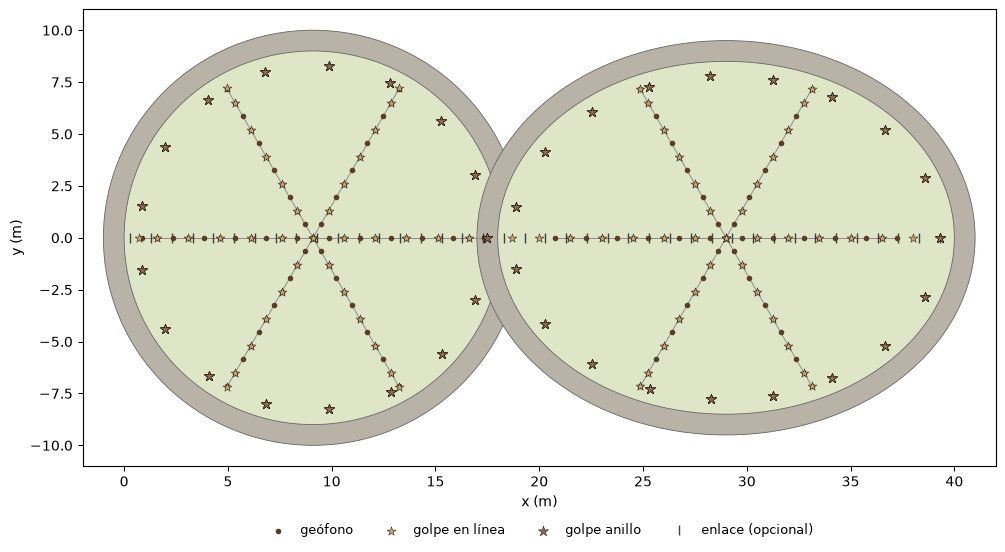

In [4]:
def draw_terraces(ax):
    for o in OVALS.values():
        ax.add_patch(Ellipse((o["cx"], o["cy"]), 2 * (o["a"] + WALL), 2 * (o["b"] + WALL), fc="#b9b2a6", ec="0.4", lw=0.6, zorder=0))
        ax.add_patch(Ellipse((o["cx"], o["cy"]), 2 * o["a"], 2 * o["b"], fc="#dfe6c8", ec="0.4", lw=0.6, zorder=0))

fig, ax = plt.subplots(figsize=(12, 5.6))
draw_terraces(ax)
for sp in spreads:
    g = sp["geophones"]
    ax.plot(g[:, 0], g[:, 1], color="0.55", lw=0.7, zorder=1)
    ax.scatter(g[:, 0], g[:, 1], s=9, color=EARTH[3], zorder=3)
    ax.scatter(sp["inline"][:, 0], sp["inline"][:, 1], marker="*", s=45, color=EARTH[1], ec="k", lw=0.3, zorder=4)
    ax.scatter(sp["ring"][:, 0], sp["ring"][:, 1], marker="*", s=60, color=EARTH[2], ec="k", lw=0.3, zorder=4)
ax.plot(link_geo[:, 0], link_geo[:, 1] - 0.0, "|", color="0.25", ms=7, zorder=2)
ax.scatter([], [], s=9, color=EARTH[3], label="geófono")
ax.scatter([], [], marker="*", s=45, color=EARTH[1], ec="k", lw=0.3, label="golpe en línea")
ax.scatter([], [], marker="*", s=60, color=EARTH[2], ec="k", lw=0.3, label="golpe anillo")
ax.plot([], [], "|", color="0.25", ms=7, label="enlace (opcional)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=9)
ax.set_aspect("equal"); ax.set_xlim(-2, 42); ax.set_ylim(-11, 11)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
plt.tight_layout(); plt.show()

## 3. Cobertura: ¿por qué 3 tendidos y golpes en el anillo?

Para una imagen 3D cada celda del subsuelo debe estar cruzada por rayos **en varias direcciones**. Comparamos tres variantes:
1. **1 tendido por óvalo** (como L1): imagen 2D.
2. **3 tendidos, solo golpes en línea**.
3. **3 tendidos + anillo** (diseño propuesto).

Se usan celdas de 1 × 1 × 0.5 m y se cuentan direcciones en sectores de 45° (0–4). Solo se cuentan las celdas bajo la grama.

In [5]:
DXY, DZ = 1.0, 0.5
xe = np.arange(-1, 41 + DXY, DXY); ye = np.arange(-10, 10 + DXY, DXY); ze = np.arange(0, 4 + DZ, DZ)
nx, ny, nz = len(xe) - 1, len(ye) - 1, len(ze) - 1
XX, YY = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2, indexing="ij")
grass = np.vectorize(lambda x, y: in_grass(x, y, 0.0))(XX, YY)

def coverage(rays):
    count = np.zeros((nx, ny, nz), int); dirs = np.zeros((nx, ny, nz, 4), bool)
    for S, G in rays:
        X = np.hypot(*(G - S))
        s = np.linspace(0, X, max(int(X / 0.1), 2))
        p = S + np.outer(s / X, G - S)
        ix = np.digitize(p[:, 0], xe) - 1; iy = np.digitize(p[:, 1], ye) - 1; iz = np.digitize(ray_depth(s, X), ze) - 1
        ok = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny) & (iz >= 0) & (iz < nz)
        cells = np.unique(np.c_[ix, iy, iz][ok], axis=0).T
        az = int((np.degrees(np.arctan2(*(G - S)[::-1])) % 180 + 22.5) // 45) % 4
        count[tuple(cells)] += 1; dirs[(*cells, np.full(cells.shape[1], az))] = True
    return count, dirs.sum(-1)

def rays_for(azimuths, use_ring):
    rays = []
    for sp in spreads:
        if sp["az"] not in azimuths: continue
        shots = np.vstack([sp["inline"], sp["ring"]]) if use_ring else sp["inline"]
        rays += [(s, g) for s in shots for g in sp["geophones"] if np.hypot(*(g - s)) > 0.3]
    return rays

designs = {"1 tendido por óvalo": rays_for([0], False),
           "3 tendidos, golpes en línea": rays_for(LINE_AZIMUTHS, False),
           "3 tendidos + anillo": rays_for(LINE_AZIMUTHS, True)}
results = {k: coverage(r) for k, r in designs.items()}

rows = []
for name, (cnt, nd) in results.items():
    row = {"diseño": name, "rayos": len(designs[name])}
    for z0, z1 in ((0, 1), (1, 2), (2, 3)):
        k = slice(int(z0 / DZ), int(z1 / DZ))
        row[f"{z0}–{z1} m"] = round(100 * (nd[grass][:, k] >= 3).mean())
    rows.append(row)
print("% del volumen bajo la grama cruzado por rayos en >= 3 direcciones")
pd.DataFrame(rows).set_index("diseño")

% del volumen bajo la grama cruzado por rayos en >= 3 direcciones


,rayos,0–1 m,1–2 m,2–3 m
diseño,,,,
1 tendido por óvalo,620,0,0,0
"3 tendidos, golpes en línea",1764,0,0,0
3 tendidos + anillo,4247,44,60,61


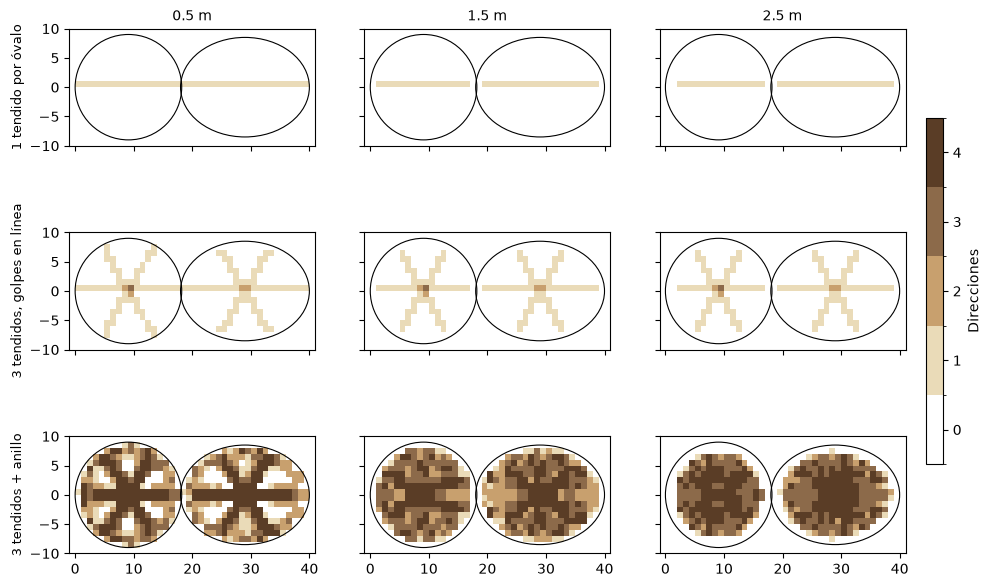

In [6]:
cmap = ListedColormap(["white"] + EARTH); norm = BoundaryNorm(np.arange(-0.5, 5), cmap.N)
depths = [0.5, 1.5, 2.5]
fig, axes = plt.subplots(3, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for r, (name, (cnt, nd)) in enumerate(results.items()):
    for c, z in enumerate(depths):
        ax = axes[r, c]
        im = ax.pcolormesh(xe, ye, np.where(grass, nd[:, :, int(z / DZ)], np.nan).T, cmap=cmap, norm=norm)
        for o in OVALS.values():
            ax.add_patch(Ellipse((o["cx"], o["cy"]), 2 * o["a"], 2 * o["b"], fill=False, ec="k", lw=0.8))
        ax.set_aspect("equal")
        if r == 0: ax.set_title(f"{z} m", fontsize=10)
        if c == 0: ax.set_ylabel(name, fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=0.6, ticks=range(5), pad=0.02); cb.set_label("Direcciones")
plt.show()

Cómo leerlo:
- **1 tendido**: solo una franja, en una dirección (2D).
- **3 tendidos sin anillo**: cada línea solo aporta rayos en su propia dirección. Solo el cruce central tiene varias, así que sigue siendo un conjunto de perfiles 2D.
- **3 tendidos + anillo**: los golpes perimetrales generan rayos oblicuos en todas las direcciones. Hay ≥3 direcciones en ~60 % del volumen a 1–3 m, sobre todo en la parte central de cada óvalo (unos 12 m de diámetro). **Este es el diseño que permite una imagen 3D a la profundidad objetivo.**

Limitaciones de cobertura:
- **0–1 m entre las líneas**: solo los rayos cortos ven tan somero, y estos van junto a los tendidos. Para el detalle 3D somero conviene GPR.
- **Borde de cada óvalo a 2–3 m**: menos cobertura, porque no se golpea sobre los muros ni fuera de la terraza. Es una limitación del sitio, no del diseño. Interpreta con cuidado los 1–2 m junto al anillo de piedra.

## 4. Sección de rayos en un tendido

Rayos del tendido E000 (eje largo del óvalo este) desde sus golpes en línea.

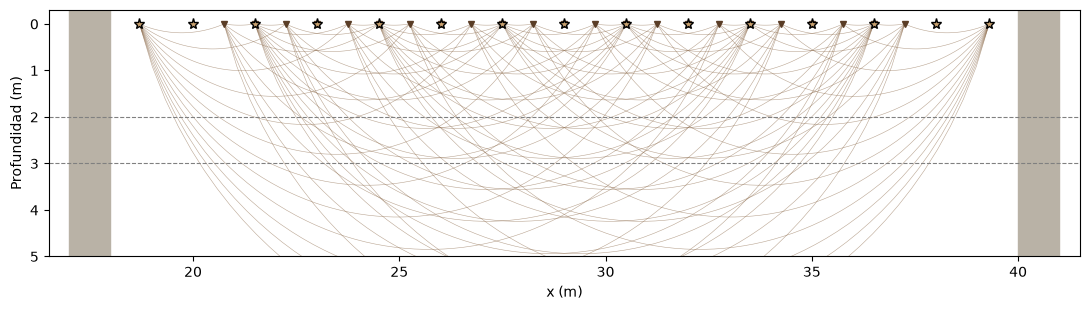

In [7]:
sp = next(s for s in spreads if s["line"] == "E000")
o = OVALS["Este"]
fig, ax = plt.subplots(figsize=(11, 3.2))
for S in sp["inline"][::2]:
    for G in sp["geophones"][::2]:
        X = np.hypot(*(G - S)); s = np.linspace(0, X, 60)
        xs = S[0] + s * np.sign(G[0] - S[0])
        ax.plot(xs, ray_depth(s, X), color=EARTH[2], lw=0.4, alpha=0.6)
ax.plot(sp["geophones"][:, 0], np.zeros(len(sp["geophones"])), "v", color=EARTH[3], ms=4)
ax.plot(sp["inline"][:, 0], np.zeros(len(sp["inline"])), "*", color=EARTH[1], mec="k", ms=8)
for z in TARGET_DEPTHS: ax.axhline(z, color="0.5", ls="--", lw=0.8)
ax.axvspan(o["cx"] - o["a"] - WALL, o["cx"] - o["a"], color="#b9b2a6"); ax.axvspan(o["cx"] + o["a"], o["cx"] + o["a"] + WALL, color="#b9b2a6")
ax.set_ylim(5, -0.3); ax.set_xlim(o["cx"] - o["a"] - WALL - 0.5, o["cx"] + o["a"] + WALL + 0.5)
ax.set_xlabel("x (m)"); ax.set_ylabel("Profundidad (m)")
plt.tight_layout(); plt.show()

## 5. Lista de replanteo

Coordenadas locales de cada geófono y punto de golpe, para replantear con estación total. Se guardan en `design/teyuna_terraces_stakeout.csv`.

In [8]:
rows = []
for sp in spreads:
    rows += [dict(tendido=sp["line"], tipo="geófono", n=i + 1, x=x, y=y) for i, (x, y) in enumerate(sp["geophones"])]
    rows += [dict(tendido=sp["line"], tipo="golpe línea", n=i + 1, x=x, y=y) for i, (x, y) in enumerate(sp["inline"])]
for name, oval in OVALS.items():
    rows += [dict(tendido=f"{name[0]}-anillo", tipo="golpe anillo", n=i + 1, x=x, y=y)
             for i, (x, y) in enumerate(ring(oval, SHOT_MARGIN, RING_SHOT_DS))]
rows += [dict(tendido="ENLACE", tipo="geófono", n=i + 1, x=x, y=y) for i, (x, y) in enumerate(link_geo)]
rows += [dict(tendido="ENLACE", tipo="golpe línea", n=i + 1, x=x, y=y) for i, (x, y) in enumerate(link_shots)]
stake = pd.DataFrame(rows).round({"x": 2, "y": 2})
stake.to_csv(OUT / "teyuna_terraces_stakeout.csv", index=False)
stake.groupby(["tendido", "tipo"]).size().unstack(fill_value=0)

tipo,geófono,golpe anillo,golpe línea
tendido,,,
E-anillo,0,19,0
E000,23,0,15
E060,23,0,13
E120,23,0,13
ENLACE,40,0,6
O-anillo,0,17,0
O000,23,0,13
O060,23,0,13
O120,23,0,13


## 6. Protocolo de campo

**Antes**
- Permisos del ICANH y de la administración del Parque, y consulta con las autoridades indígenas.
- Levantamiento con estación total del borde interior de cada anillo de piedra. Ajusta `OVALS` y vuelve a ejecutar el notebook.

**Equipo y registro**
| Parámetro | Valor |
|---|---|
| Canales | 24 (23 geófonos + 1 de referencia junto a la placa) |
| Geófonos | 28–40 Hz verticales, clavados en tierra, nunca entre piedras |
| Fuente | martillo de 2–4 kg con interruptor, placa de aluminio o caucho duro, siempre sobre grama |
| Muestreo / registro | 0.0625 ms (16 kHz) / 0.25 s, pre-trigger de 10–20 ms, filtros apagados |
| Golpes | 8 por posición, **guardando cada golpe** por separado |

**Orden de trabajo por óvalo**
1. Comprueba el trigger: 5 golpes en el mismo punto, con primeros arribos alineados a mejor de 0.05 ms.
2. Tendido 000: todos sus golpes en línea, luego todo el anillo.
3. Mueve los geófonos al tendido 060 y repite; luego el 120.
4. Repite 2 golpes del primer tendido al final, como control de que el sistema no cambió.
5. (Opcional) Línea de enlace a lo largo del eje de 40 m, con 2 tendidos y los 6 golpes indicados. Pasa bajo el muro de unión y alcanza más de 3 m con los offsets largos.

**Nombres de archivo**: `<tendido>_<tipo><n>_h<golpe>.dat` (por ejemplo `E060_L07_h03.dat` o `E060_R12_h05.dat`), y una bitácora con la hora, la humedad del suelo (llovió o no) y cualquier observación.

## 7. Limitaciones
- **Modelo de velocidad ilustrativo**: con contactos bruscos la cobertura cambia, pero la regla "offset de 8–12 m para 2–3 m" se mantiene.
- **Resolución**: unos 0.5–1 m. Detecta el contacto relleno/natural y cambios grandes, no muros enterrados (para eso usa GPR).
- **Capas lentas bajo rápidas**: no se detectan.
- **Bordes junto al anillo de piedra**: menor cobertura en profundidad.
- **Inversión 3D**: pyGIMLi, con malla 3D (requiere `tetgen`) o malla regular. Refrapy solo trabaja en 2D, pero cada tendido puede invertirse en 2D como control.